In [1]:
import ee, geemap, pandas as pd, numpy as np, rasterio, folium
ee.Initialize(project="moon-analog")
print("ready")

ready


In [2]:
import os, urllib.request

os.makedirs(r"D:\moon-analog\data", exist_ok=True)
url = "https://pgda.gsfc.nasa.gov/data/LOLA_5mpp/Site04/Site04_final_adj_5mpp_surf.tif"
out = r"D:\moon-analog\data\Site04_final_adj_5mpp_surf.tif"

urllib.request.urlretrieve(url, out)
print("done, size (MB):", round(os.path.getsize(out) / 1e6, 1))

done, size (MB): 41.0


In [4]:
import pandas as pd, numpy as np, rasterio
from rasterio.windows import Window
from rasterio.enums import Resampling

def site_stats(dem_path, name, half_km=5, target_res=30):
    with rasterio.open(dem_path) as src:
        res = src.res[0]                              # meters per pixel (5 for these files)
        print("file size (pixels):", src.width, "x", src.height, "| pixel size (m):", res)
        half = int(half_km * 1000 / res)              # pixels from center to patch edge
        f = max(int(round(target_res / res)), 1)      # 6 means 5 m becomes 30 m
        x0 = max(src.width // 2 - half, 0)
        y0 = max(src.height // 2 - half, 0)
        w = min(2 * half, src.width - x0);  w -= w % f
        h = min(2 * half, src.height - y0); h -= h % f
        elev = src.read(1, window=Window(x0, y0, w, h),
                        out_shape=(h // f, w // f),
                        resampling=Resampling.average, masked=True)
    elev = elev.astype("float64").filled(np.nan)
    gy, gx = np.gradient(elev, target_res)
    slope = np.degrees(np.arctan(np.hypot(gx, gy)))
    s = slope[~np.isnan(slope)]
    return {
        "site": name,
        "elev_min_m": round(float(np.nanmin(elev)), 1),
        "elev_max_m": round(float(np.nanmax(elev)), 1),
        "slope_median_deg": round(float(np.median(s)), 1),
        "slope_p90_deg": round(float(np.percentile(s, 90)), 1),
        "pct_under_10deg": round(float((s < 10).mean() * 100), 1),
    }

rows = [site_stats(r"D:\moon-analog\data\Site04_final_adj_5mpp_surf.tif", "Site04 Shackleton rim")]
moon_targets = pd.DataFrame(rows)
moon_targets.to_csv("moon_targets.csv", index=False)
moon_targets

file size (pixels): 3200 x 3200 | pixel size (m): 5.0


,site,elev_min_m,elev_max_m,slope_median_deg,slope_p90_deg,pct_under_10deg
0,Site04 Shackleton rim,-2233.8,1737.8,28.7,32.9,6.1


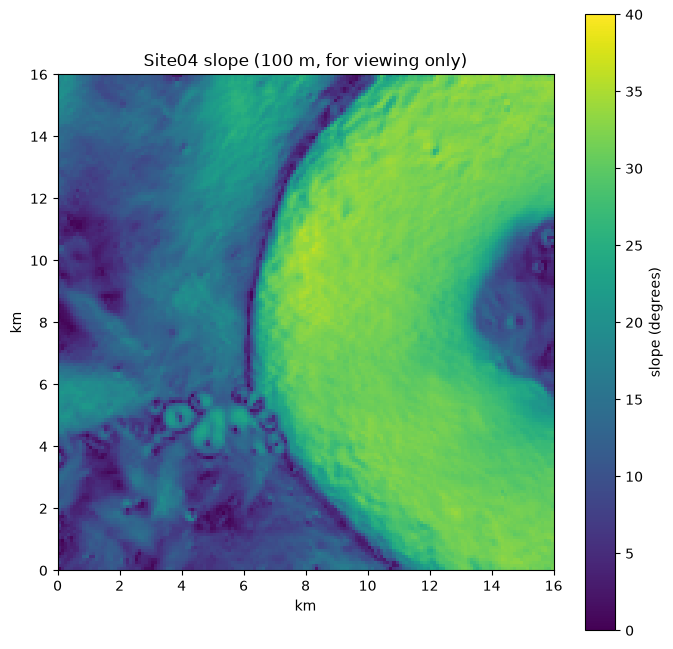

file covers about 16.0 x 16.0 km


In [5]:
import matplotlib.pyplot as plt

path = r"D:\moon-analog\data\Site04_final_adj_5mpp_surf.tif"
f = 20   # 5 m pixels averaged up to 100 m, only for viewing
with rasterio.open(path) as src:
    elev = src.read(1, out_shape=(src.height // f, src.width // f),
                    resampling=Resampling.average, masked=True)
    km_w, km_h = src.width * src.res[0] / 1000, src.height * src.res[0] / 1000
elev = elev.astype("float64").filled(np.nan)
gy, gx = np.gradient(elev, 100)
slope_view = np.degrees(np.arctan(np.hypot(gx, gy)))

plt.figure(figsize=(8, 8))
plt.imshow(slope_view, cmap="viridis", vmin=0, vmax=40, extent=[0, km_w, 0, km_h])
plt.colorbar(label="slope (degrees)")
plt.xlabel("km"); plt.ylabel("km")
plt.title("Site04 slope (100 m, for viewing only)")
plt.show()
print("file covers about", round(km_w, 1), "x", round(km_h, 1), "km")

In [6]:
def patch_stats(dem_path, name, x_km, y_km, target_res=30):
    with rasterio.open(dem_path) as src:
        res = src.res[0]
        f = max(int(round(target_res / res)), 1)
        km_h = src.height * res / 1000
        col0, col1 = int(x_km[0] * 1000 / res), int(x_km[1] * 1000 / res)
        row0 = int((km_h - y_km[1]) * 1000 / res)     # map y counts up from the bottom
        row1 = int((km_h - y_km[0]) * 1000 / res)
        w = (col1 - col0); w -= w % f
        h = (row1 - row0); h -= h % f
        elev = src.read(1, window=Window(col0, row0, w, h),
                        out_shape=(h // f, w // f),
                        resampling=Resampling.average, masked=True)
    elev = elev.astype("float64").filled(np.nan)
    gy, gx = np.gradient(elev, target_res)
    slope = np.degrees(np.arctan(np.hypot(gx, gy)))
    s = slope[~np.isnan(slope)]
    return {
        "site": name,
        "elev_min_m": round(float(np.nanmin(elev)), 1),
        "elev_max_m": round(float(np.nanmax(elev)), 1),
        "slope_median_deg": round(float(np.median(s)), 1),
        "slope_p90_deg": round(float(np.percentile(s, 90)), 1),
        "slope_std_deg": round(float(s.std()), 1),     # a simple roughness measure
        "pct_under_10deg": round(float((s < 10).mean() * 100), 1),
    }

path = r"D:\moon-analog\data\Site04_final_adj_5mpp_surf.tif"
rows = [
    patch_stats(path, "Site04 outer rim terrain", x_km=(0, 5), y_km=(7, 12)),
    patch_stats(path, "Site04 crater wall",       x_km=(8, 14), y_km=(7, 14)),
]
moon_targets = pd.DataFrame(rows)
moon_targets.to_csv("moon_targets.csv", index=False)
moon_targets

,site,elev_min_m,elev_max_m,slope_median_deg,slope_p90_deg,slope_std_deg,pct_under_10deg
0,Site04 outer rim terrain,551.9,1457.2,11.5,17.2,4.9,41.3
1,Site04 crater wall,-2597.4,1423.5,31.5,33.7,4.4,0.6


In [2]:
def patch_stats(dem_path, name, x_km, y_km, target_res=30):
    with rasterio.open(dem_path) as src:
        res = src.res[0]
        f = max(int(round(target_res / res)), 1)
        km_h = src.height * res / 1000
        col0, col1 = int(x_km[0] * 1000 / res), int(x_km[1] * 1000 / res)
        row0 = int((km_h - y_km[1]) * 1000 / res)
        row1 = int((km_h - y_km[0]) * 1000 / res)
        w = (col1 - col0); w -= w % f
        h = (row1 - row0); h -= h % f
        elev = src.read(1, window=Window(col0, row0, w, h),
                        out_shape=(h // f, w // f),
                        resampling=Resampling.average, masked=True)
    elev = elev.astype("float64").filled(np.nan)
    gy, gx = np.gradient(elev, target_res)
    slope = np.degrees(np.arctan(np.hypot(gx, gy)))
    s = slope[~np.isnan(slope)]
    return {
        "site": name,
        "elev_min_m": round(float(np.nanmin(elev)), 1),
        "elev_max_m": round(float(np.nanmax(elev)), 1),
        "slope_mean_deg": round(float(s.mean()), 1),        # new line
        "slope_median_deg": round(float(np.median(s)), 1),
        "slope_p90_deg": round(float(np.percentile(s, 90)), 1),
        "slope_std_deg": round(float(s.std()), 1),
        "pct_under_10deg": round(float((s < 10).mean() * 100), 1),
    }

In [12]:
path = r"D:\moon-analog\data\Site04_final_adj_5mpp_surf.tif"
rows = [
    patch_stats(path, "Site04 outer rim terrain", x_km=(0, 5), y_km=(7, 12)),
    patch_stats(path, "Site04 crater wall",       x_km=(8, 14), y_km=(7, 14)),
]
moon_targets = pd.DataFrame(rows)
moon_targets.to_csv("moon_targets.csv", index=False)
moon_targets

,site,elev_min_m,elev_max_m,slope_mean_deg,slope_median_deg,slope_p90_deg,slope_std_deg,pct_under_10deg
0,Site04 outer rim terrain,551.9,1457.2,11.0,11.5,17.2,4.9,41.3
1,Site04 crater wall,-2597.4,1423.5,30.4,31.5,33.7,4.4,0.6


In [14]:
import ee, pandas as pd, numpy as np, time
ee.Initialize(project="moon-analog")

dem_col = ee.ImageCollection("COPERNICUS/DEM/GLO30_2024_1").select("DEM")
dem_proj = dem_col.first().projection()
dem = dem_col.mosaic().setDefaultProjection(dem_proj)
slope30 = ee.Terrain.slope(dem).rename("slope").setDefaultProjection(dem_proj)

lst = ee.ImageCollection("MODIS/061/MOD11A2").filterDate("2024-01-01", "2025-01-01")
modis_proj = lst.first().select("LST_Day_1km").projection()
tmax = (lst.select("LST_Day_1km").max().multiply(0.02).subtract(273.15)
        .rename("tmax_c").setDefaultProjection(modis_proj))
tmin = (lst.select("LST_Night_1km").min().multiply(0.02).subtract(273.15)
        .rename("tmin_c").setDefaultProjection(modis_proj))

slope_cells = slope30.reduceResolution(
    reducer=ee.Reducer.mean().combine(ee.Reducer.stdDev(), sharedInputs=True),
    maxPixels=65535
).reproject(crs="EPSG:4326", scale=5000)

temp_cells = tmax.addBands(tmin).reduceResolution(
    reducer=ee.Reducer.mean(), maxPixels=1024
).reproject(crs="EPSG:4326", scale=5000)

cells = slope_cells.addBands(temp_cells)
print("layers ready")

def measure_tile(west, south, east, north):
    region = ee.Geometry.Rectangle([west, south, east, north])
    fc = cells.sample(region=region, scale=5000, geometries=True)
    feats = fc.getInfo()["features"]
    return

layers ready


In [3]:
import ee, pandas as pd, numpy as np, time
ee.Initialize(project="moon-analog")

# Elevation and slope (30 m)
dem_col = ee.ImageCollection("COPERNICUS/DEM/GLO30_2024_1").select("DEM")
dem_proj = dem_col.first().projection()
dem = dem_col.mosaic().setDefaultProjection(dem_proj)
slope30 = ee.Terrain.slope(dem).rename("slope").setDefaultProjection(dem_proj)

# Ground temperature
lst = ee.ImageCollection("MODIS/061/MOD11A2").filterDate("2024-01-01", "2025-01-01")
modis_proj = lst.first().select("LST_Day_1km").projection()
tmax = (lst.select("LST_Day_1km").max().multiply(0.02).subtract(273.15)
        .rename("tmax_c").setDefaultProjection(modis_proj))
tmin = (lst.select("LST_Night_1km").min().multiply(0.02).subtract(273.15)
        .rename("tmin_c").setDefaultProjection(modis_proj))

# Vegetation
ndvi_col = ee.ImageCollection("MODIS/061/MOD13A2").filterDate("2024-01-01", "2025-01-01")
ndvi_proj = ndvi_col.first().select("NDVI").projection()
ndvi_max = (ndvi_col.select("NDVI").max().multiply(0.0001)
            .rename("ndvi_max").setDefaultProjection(ndvi_proj))

# Water
gsw = ee.Image("JRC/GSW1_4/GlobalSurfaceWater").select("occurrence")
water = gsw.unmask(0).rename("water_pct").setDefaultProjection(gsw.projection())

# 5 km cells
slope_cells = slope30.reduceResolution(
    reducer=ee.Reducer.mean().combine(ee.Reducer.stdDev(), sharedInputs=True),
    maxPixels=65535
).reproject(crs="EPSG:4326", scale=5000)

temp_cells = tmax.addBands(tmin).reduceResolution(
    reducer=ee.Reducer.mean(), maxPixels=1024
).reproject(crs="EPSG:4326", scale=5000)

veg_cells = ndvi_max.reduceResolution(
    reducer=ee.Reducer.mean(), maxPixels=1024
).reproject(crs="EPSG:4326", scale=5000)

water_cells = water.reduceResolution(
    reducer=ee.Reducer.mean(), maxPixels=65535
).reproject(crs="EPSG:4326", scale=5000)

cells = slope_cells.addBands(temp_cells).addBands(veg_cells).addBands(water_cells)
print("layers ready")

def measure_tile(west, south, east, north):
    region = ee.Geometry.Rectangle([west, south, east, north])
    fc = cells.sample(region=region, scale=5000, geometries=True, tileScale=4)
    feats = fc.getInfo()["features"]
    return [dict(f["properties"],
                 lon=f["geometry"]["coordinates"][0],
                 lat=f["geometry"]["coordinates"][1]) for f in feats]

def measure(name, west, south, east, north, step=0.25):
    t0 = time.time()
    rows = []
    for w in np.arange(west, east, step):
        for s in np.arange(south, north, step):
            box = (float(w), float(s), float(min(w + step, east)), float(min(s + step, north)))
            try:
                rows += measure_tile(*box)
            except Exception as e:
                print(name, [round(x, 2) for x in box], "skipped:", str(e)[:80])
    d = pd.DataFrame(rows).dropna()
    d["region"] = name
    print(name, "->", len(d), "cells,", round(time.time() - t0), "s")
    return d

regions = {
    "Ladakh/Changthang":         (78.0, 33.0, 79.0, 34.0),
    "Tibet Qiangtang":           (84.0, 33.5, 85.0, 34.5),
    "Pamir plateau":             (73.0, 38.0, 74.0, 39.0),
    "Iceland highlands":         (-18.5, 64.5, -17.5, 65.5),
    "Antarctic Dry Valleys":     (161.0, -77.8, 162.0, -77.2),
    "Andean Puna":               (-68.0, -23.5, -67.0, -22.5),
    "Atacama":                   (-69.5, -24.5, -68.5, -23.5),
    "Lut Desert":                (59.0, 30.5, 60.0, 31.5),
    "Death Valley":              (-117.2, 36.0, -116.2, 37.0),
    "Mauna Kea (known analog)":  (-155.8, 19.5, -155.3, 20.0),
}

all_dfs = []
for name, box in regions.items():
    all_dfs.append(measure(name, *box))
    pd.concat(all_dfs).to_csv("earth_cells.csv", index=False)   # saves after every region
df = pd.concat(all_dfs, ignore_index=True)
print(list(df.columns))

layers ready
Ladakh/Changthang -> 484 cells, 41 s
Tibet Qiangtang -> 484 cells, 37 s
Pamir plateau -> 506 cells, 41 s
Iceland highlands -> 484 cells, 37 s
Antarctic Dry Valleys -> 0 cells, 21 s
Andean Puna -> 484 cells, 32 s
Atacama -> 484 cells, 29 s
Lut Desert -> 484 cells, 25 s
Death Valley -> 484 cells, 26 s
Mauna Kea (known analog) -> 121 cells, 5 s
['ndvi_max', 'slope_mean', 'slope_stdDev', 'tmax_c', 'tmin_c', 'water_pct', 'lon', 'lat', 'region']


In [4]:
def score(df, t_mean, t_std, w=(0.30, 0.15, 0.30, 0.25)):
    d = df.copy()
    d["trange_c"] = d["tmax_c"] - d["tmin_c"]
    d["d_mean"] = (abs(d["slope_mean"] - t_mean) / 10).clip(0, 1)
    d["d_std"] = (abs(d["slope_stdDev"] - t_std) / 5).clip(0, 1)
    rank01 = lambda s: (s - s.min()) / (s.max() - s.min() + 1e-9)
    d["d_cold"] = rank01(d["tmin_c"])
    d["d_swing"] = 1 - rank01(d["trange_c"])
    d["distance"] = (w[0]*d["d_mean"] + w[1]*d["d_std"] +
                     w[2]*d["d_cold"] + w[3]*d["d_swing"])
    return d.sort_values("distance")

bare = df[(df["ndvi_max"] < 0.10) & (df["water_pct"] < 5)]
print(len(bare), "of", len(df), "cells are bare, dry ground")

rim = score(bare, t_mean=11.0, t_std=4.9)
wall = score(bare, t_mean=30.4, t_std=4.4)

cols = ["region", "lat", "lon", "slope_mean", "slope_stdDev", "tmin_c", "tmax_c", "distance"]
print(rim[cols].head(15).round(2).to_string())
print()
print(rim.groupby("region")["distance"].agg(["count", "min", "median"]).round(2))

1590 of 4015 cells are bare, dry ground
                 region    lat    lon  slope_mean  slope_stdDev  tmin_c  tmax_c  distance
593     Tibet Qiangtang  34.43  84.06        8.71          7.36  -31.00   37.39      0.20
51    Ladakh/Changthang  33.26  78.09       10.14          7.47  -27.70   36.50      0.20
135   Ladakh/Changthang  33.04  78.31        9.03          5.54  -26.64   33.95      0.20
1279      Pamir plateau  38.74  73.64       11.28          8.00  -27.94   35.40      0.20
1411      Pamir plateau  38.74  73.91       11.65          7.47  -26.81   34.31      0.22
1193      Pamir plateau  38.92  73.41       10.35          7.68  -25.35   37.08      0.23
1278      Pamir plateau  38.74  73.59        8.62          7.24  -27.05   37.15      0.25
594     Tibet Qiangtang  34.43  84.10        6.72          7.32  -30.57   39.08      0.25
263   Ladakh/Changthang  33.04  78.58       13.43          7.85  -28.33   34.76      0.26
299   Ladakh/Changthang  33.71  78.63       11.54          8

In [8]:
print(df.groupby("region").size())
print(list(df.columns))

region
Andean Puna                 484
Atacama                     484
Death Valley                484
Iceland highlands           484
Ladakh/Changthang           484
Lut Desert                  484
Mauna Kea (known analog)    121
Pamir plateau               506
Tibet Qiangtang             484
dtype: int64
['ndvi_max', 'slope_mean', 'slope_stdDev', 'tmax_c', 'tmin_c', 'water_pct', 'lon', 'lat', 'region']


In [10]:
import folium
from matplotlib import colormaps, colors

top = rim.head(50)
lo, hi = top.distance.min(), top.distance.max()
col = lambda x: colors.to_hex(colormaps["RdYlGn_r"]((x - lo) / (hi - lo + 1e-9)))

m = folium.Map(location=[top.lat.mean(), top.lon.mean()], zoom_start=8, tiles="OpenStreetMap")
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri, Maxar, Earthstar Geographics", name="Satellite",
).add_to(m)

for _, r in top.iterrows():
    folium.CircleMarker(
        [r.lat, r.lon], radius=6, color=col(r.distance), fill=True, fill_opacity=0.8,
        popup=f"{r.region} | score {r.distance:.2f} | slope {r.slope_mean:.1f} deg | night min {r.tmin_c:.0f} C"
    ).add_to(m)

m.fit_bounds([[top.lat.min(), top.lon.min()], [top.lat.max(), top.lon.max()]])
folium.LayerControl().add_to(m)
m.save("analog_map.html")
print("saved")

saved


In [11]:
import os, time
print(rim.head(50)["region"].value_counts())
print("regions in rim:", rim["region"].nunique())
p = os.path.abspath("analog_map.html")
print(p)
print("saved:", time.ctime(os.path.getmtime(p)))

region
Pamir plateau        16
Andean Puna          13
Ladakh/Changthang    10
Tibet Qiangtang       7
Iceland highlands     4
Name: count, dtype: int64
regions in rim: 9
d:\moon-analog\analog_map.html
saved: Sat Nov 14 18:22:37 2026


In [12]:
import shutil, os

REPO = r"C:\Users\niran\OneDrive\Documents\GitHub\moon-analog"

files = ["analog.ipynb", "analog_map.html", "earth_cells.csv", "moon_targets.csv", "top_rim.csv"]
for f in files:
    if os.path.exists(f):
        shutil.copy(f, REPO)
        print("copied", f)
    else:
        print("not found:", f)

copied analog.ipynb
copied analog_map.html
copied earth_cells.csv
copied moon_targets.csv
copied top_rim.csv
